# BEPAD: get the data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/01_get_the_data.ipynb)

Load a few windows, look at one, and choose windows by their metadata. About 2 minutes.
Documentation: [Get the data](https://bepad.readthedocs.io/en/latest/get_data.html) · [Understand a window](https://bepad.readthedocs.io/en/latest/window.html).

In [1]:
%pip install -q "bepad>=0.2.0"
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"     # quieter downloads

Note: you may need to restart the kernel to use updated packages.


In [2]:
import bepad
bepad.__version__

'0.2.0'

## 1. Load a few windows

[`bepad.load`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.load) downloads only what you ask for (here 20 test windows of the Texas and Colombia
networks) and caches it, so the next call is instant. `max_windows` is a fixed random sample per
network.

In [3]:
test = bepad.load("test", networks=["tx", "CM"], max_windows=20)
test

/groups/igonin/ecastillo/anaconda3/envs/hypogt-h100/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<bepad.Split 40 windows, 10188 picks, 2 networks, labels=True>

One **window** ([`WindowData`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.data.WindowData)) is one association problem:
its `picks`, the `stations` operating in it, and the true earthquakes (`events`). The label of every
pick is `event_idx`: its earthquake (0, 1, 2 …) or **−1 for noise**. Columns:
[File format](https://bepad.readthedocs.io/en/latest/reference/format.html).

In [4]:
w = test[0]
print(w.window_id)
w.picks.head()

CM.test.ev-sparse__noise-low.00009


,window_id,pick_idx,station,phase,t_rel_s,time,event_idx,pick_type,real,prob,sigma_s,in_scorable_event,src_event_id,src_pick_id
0,CM.test.ev-sparse__noise-low.00009,0,CM.YOT,P,18.014663,2020-03-31 11:59:42.653447182,0,real,1,0.795906,0.411337,True,smi:local/SGC2020iklkkd,smi:local/Pick/CM.YOT.00.HHZ/20200428T235947.4...
1,CM.test.ev-sparse__noise-low.00009,1,CM.JAMC,P,21.907077,2020-03-31 11:59:46.545860874,-1,noise,0,0.000000,NaN,False,None,None
2,CM.test.ev-sparse__noise-low.00009,2,CM.PAL,P,22.420786,2020-03-31 11:59:47.059570182,0,real,1,0.740401,0.528185,True,smi:local/SGC2020iklkkd,smi:local/Pick/CM.PAL.00.HHZ/20200428T235951.8...
3,CM.test.ev-sparse__noise-low.00009,3,CM.JAMC,P,24.776631,2020-03-31 11:59:49.415415182,0,real,1,0.735027,0.541093,True,smi:local/SGC2020iklkkd,smi:local/Pick/CM.JAMC.00.HHZ/20200428T235954....
4,CM.test.ev-sparse__noise-low.00009,4,CM.YOT,S,26.159430,2020-03-31 11:59:50.798214182,0,real,1,0.795906,0.411337,True,smi:local/SGC2020iklkkd,smi:local/Pick/CM.YOT.00.HHN/20200428T235955.5...


In [5]:
w.picks.pick_type.value_counts()      # real, generated (plausible extra arrivals) and noise picks

pick_type
real         23
generated     3
noise         2
Name: count, dtype: int64

In [6]:
w.events[["event_idx", "origin_time", "latitude", "longitude", "depth", "magnitude"]]

,event_idx,origin_time,latitude,longitude,depth,magnitude
0,0,2020-03-31 11:59:31.206716182,4.18,-76.89,13130.0,1.71
1,1,2020-03-31 12:00:03.000000000,7.41,-73.54,105400.0,1.12


## 2. Look at a window

[`plot_window_anatomy`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.plots.plot_window_anatomy): (a) where the earthquakes and
stations are, (b) every pick at its distance from its earthquake, (c) picks by type. The
associator's job: find which picks belong together.

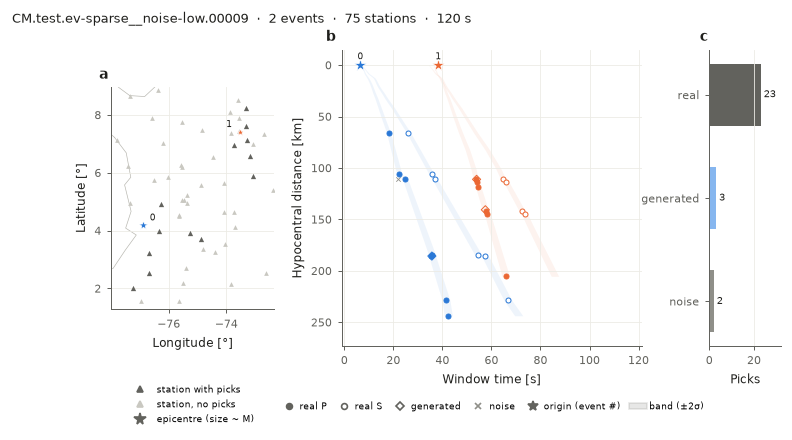

In [7]:
from bepad.plots import plot_window_anatomy

plot_window_anatomy(w, model=test.release.label_model);

## 3. Difficulty: scenarios

Windows come in 38 scenarios, each answering three questions: **which earthquakes** (at random, a
**sequence** of aftershocks and foreshocks, or outside the network), **how many** (1 to 20) and
**how much noise**. Here the random ones: more earthquakes at once (left to right), more noise
(top to bottom). Each panel shows its `window_id`.
[`plot_scenario_grid`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.plots.plot_scenario_grid) · [Scenarios](https://bepad.readthedocs.io/en/latest/scenarios.html).

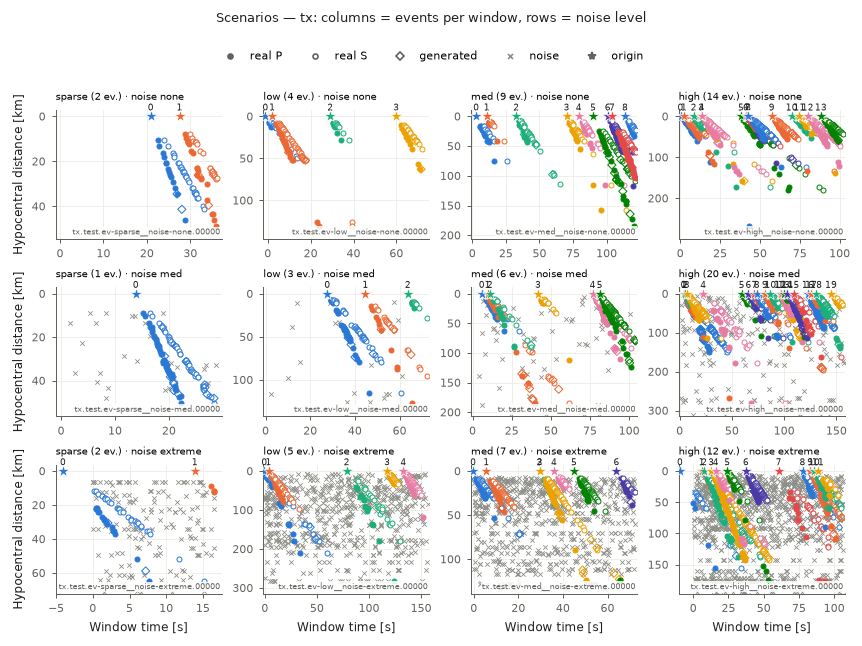

In [8]:
from bepad.plots import plot_scenario_grid

grid = [f"tx.test.ev-{ev}__noise-{noise}.00000" for ev in ("sparse", "low", "med", "high")
        for noise in ("none", "med", "extreme")]
plot_scenario_grid(bepad.load("test", window_ids=grid), "tx");

**Sequences**: an earthquake and its nearest earthquakes, timed like aftershocks (Omori's law).
Four types: mainshock first, foreshocks then mainshock, late in a sequence (no mainshock), two
sequences. Large stars are mainshocks.
[`plot_sequence_types`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.plots.plot_sequence_types) · [Sequences](https://bepad.readthedocs.io/en/latest/scenarios.html#sequences).

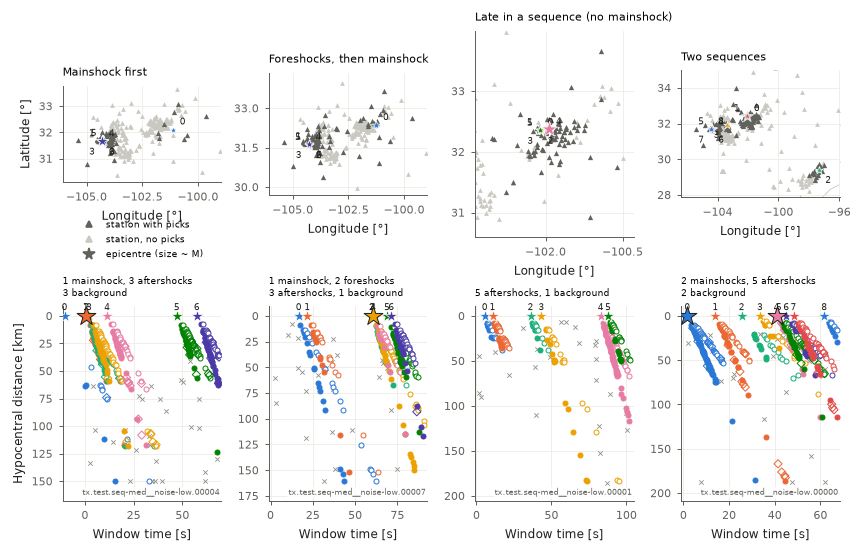

In [9]:
from bepad.plots import plot_sequence_types

seq = bepad.load("test", networks=["tx"], scenarios=["seq-med__noise-low"])
plot_sequence_types(seq, "tx");

## 4. Choose windows

Every window has a row of metadata. Read it with [`Release.table`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.data.Release.table)
(small, no picks), filter it, then load only the windows you chose with `window_ids`. All columns:
[windows table](https://bepad.readthedocs.io/en/latest/reference/format.html#windows).

In [10]:
meta = test.release.table("test", "windows", networks=["tx", "CM"])
meta[["window_id", "selection", "n_events_level", "noise_level", "sequence_type", "n_events", "max_concurrent_events"]].head()

,window_id,selection,n_events_level,noise_level,sequence_type,n_events,max_concurrent_events
0,CM.test.ev-sparse__noise-none.00000,random,sparse,none,None,2,1
1,CM.test.ev-sparse__noise-none.00001,random,sparse,none,None,1,1
2,CM.test.ev-sparse__noise-none.00002,random,sparse,none,None,1,1
3,CM.test.ev-sparse__noise-none.00003,random,sparse,none,None,1,1
4,CM.test.ev-sparse__noise-none.00004,random,sparse,none,None,2,1


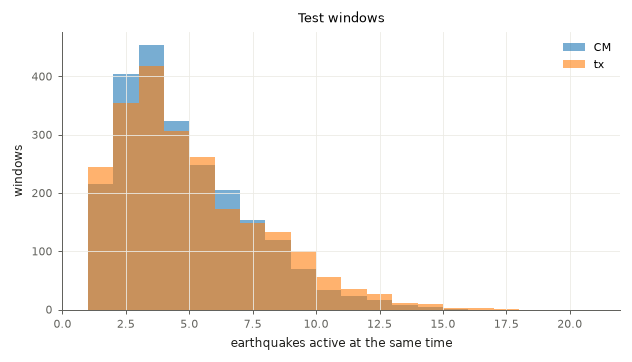

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
for net, g in meta.groupby("network"):
    ax.hist(g.max_concurrent_events, bins=range(1, 22), alpha=0.6, label=net)
ax.set(xlabel="earthquakes active at the same time", ylabel="windows", title="Test windows")
ax.legend();

80 crowded, noisy sequence windows


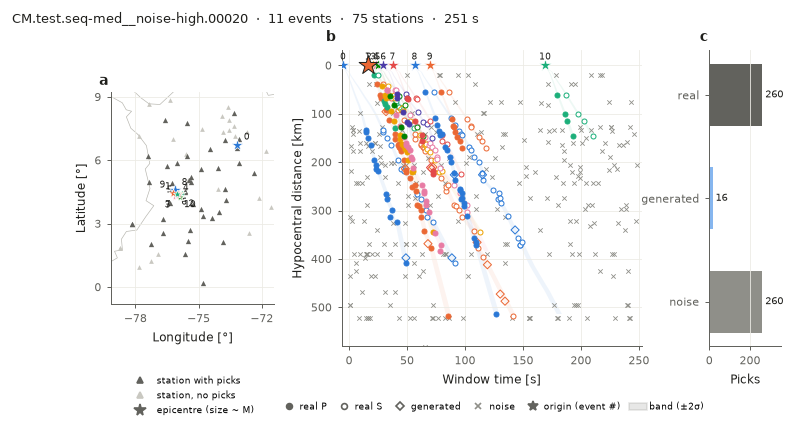

In [12]:
crowded = meta[(meta.selection == "sequence") & (meta.max_concurrent_events >= 8) & (meta.noise_level == "high")]
hard = bepad.load("test", window_ids=crowded.window_id)
print(len(crowded), "crowded, noisy sequence windows")
plot_window_anatomy(hard[0], model=hard.release.label_model);

## Next

* [Benchmark your associator](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/02_benchmark.ipynb)
  (notebook) · [Train a model](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/03_train.ipynb) (notebook)
* More filters (by station) and loading without the package: [Get the data](https://bepad.readthedocs.io/en/latest/get_data.html)
* How much data, and statistics: [Dataset statistics](https://bepad.readthedocs.io/en/latest/reference/statistics.html)